# 01 - EDA & Data Prep
**Goal:** understand the Home Credit data, clean it, build a few risk features, and create a train/test split.

**Business problem:** a lender wants to predict the probability that an applicant defaults (`TARGET = 1`) so it can approve/reject loans and set cut-offs.

**Data:** download `application_train.csv` from the [Home Credit Default Risk](https://www.kaggle.com/c/home-credit-default-risk/data) competition and put it in `data/`.

In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split

DATA_DIR = Path("application_train")
PROC_DIR = DATA_DIR / "processed"
PROC_DIR.mkdir(parents=True, exist_ok=True)

ID_COL, TARGET = "SK_ID_CURR", "TARGET"
RANDOM_STATE = 42

In [4]:
df = pd.read_csv("application_train.csv")
print("Shape:", df.shape)
df.head()

Shape: (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## 1. Target (default) rate

Default rate: 8.07%  ->  heavily imbalanced


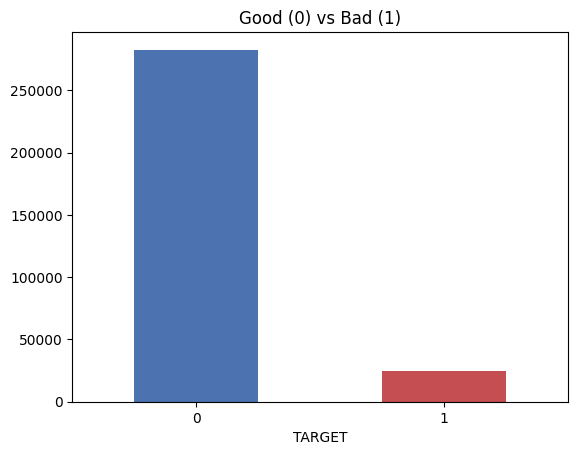

In [5]:
default_rate = df[TARGET].mean()
print(f"Default rate: {default_rate:.2%}  ->  heavily imbalanced")

df[TARGET].value_counts().plot(kind="bar", color=["#4c72b0", "#c44e52"])
plt.title("Good (0) vs Bad (1)")
plt.xticks(rotation=0)
plt.show()

## 2. Missing values

In [6]:
missing = df.isna().mean().sort_values(ascending=False)
print("Columns with >60% missing:", (missing > 0.6).sum())
missing.head(15)

Columns with >60% missing: 17


COMMONAREA_MEDI             0.698723
COMMONAREA_AVG              0.698723
COMMONAREA_MODE             0.698723
NONLIVINGAPARTMENTS_MODE    0.694330
NONLIVINGAPARTMENTS_AVG     0.694330
NONLIVINGAPARTMENTS_MEDI    0.694330
FONDKAPREMONT_MODE          0.683862
LIVINGAPARTMENTS_MODE       0.683550
LIVINGAPARTMENTS_AVG        0.683550
LIVINGAPARTMENTS_MEDI       0.683550
FLOORSMIN_AVG               0.678486
FLOORSMIN_MODE              0.678486
FLOORSMIN_MEDI              0.678486
YEARS_BUILD_MEDI            0.664978
YEARS_BUILD_MODE            0.664978
dtype: float64

## 3. Cleaning
- `DAYS_EMPLOYED = 365243` is a known placeholder (pensioners / unemployed), not a real value -> set to missing.
- `CODE_GENDER = "XNA"` is only a few rows -> set to missing.

In [7]:
print("Rows with DAYS_EMPLOYED = 365243:", (df["DAYS_EMPLOYED"] == 365243).sum())

df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(365243, np.nan)
df["CODE_GENDER"] = df["CODE_GENDER"].replace("XNA", np.nan)

Rows with DAYS_EMPLOYED = 365243: 55374


## 4. Feature engineering (risk ratios lenders actually use)
| Feature | Meaning |
|---|---|
| `AGE_YEARS` | applicant age |
| `YEARS_EMPLOYED` | job tenure |
| `CREDIT_TO_INCOME` | loan size vs income |
| `ANNUITY_TO_INCOME` | EMI burden (like DTI) |
| `CREDIT_TO_GOODS` | how much of the goods price is financed |
| `CREDIT_TERM` | annuity / credit (inverse of loan tenure) |
| `EMPLOYED_TO_AGE` | share of life employed |

In [8]:
df["AGE_YEARS"] = -df["DAYS_BIRTH"] / 365
df["YEARS_EMPLOYED"] = -df["DAYS_EMPLOYED"] / 365
df["CREDIT_TO_INCOME"] = df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"]
df["ANNUITY_TO_INCOME"] = df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"]
df["CREDIT_TO_GOODS"] = df["AMT_CREDIT"] / df["AMT_GOODS_PRICE"]
df["CREDIT_TERM"] = df["AMT_ANNUITY"] / df["AMT_CREDIT"]
df["EMPLOYED_TO_AGE"] = df["YEARS_EMPLOYED"] / df["AGE_YEARS"]

# raw day columns are now redundant
df = df.drop(columns=["DAYS_BIRTH", "DAYS_EMPLOYED"])
df = df.replace([np.inf, -np.inf], np.nan)

## 5. Drop columns with more than 60% missing

In [9]:
miss = df.isna().mean()
drop_cols = miss[(miss > 0.60)].index.difference([ID_COL, TARGET]).tolist()
print(f"Dropping {len(drop_cols)} columns")
df = df.drop(columns=drop_cols)
print("Final shape:", df.shape)

Dropping 17 columns
Final shape: (307511, 110)


## 6. Train / test split
Home Credit has no application date, so a true out-of-time split is not possible. We use a **stratified 70/30 split** so both sets keep the same default rate.

> In a real bank you would also hold out an out-of-time sample (e.g. the latest 3 months).

In [10]:
train, test = train_test_split(df, test_size=0.30, stratify=df[TARGET], random_state=RANDOM_STATE)

print(f"Train: {train.shape}  default rate {train[TARGET].mean():.2%}")
print(f"Test : {test.shape}  default rate {test[TARGET].mean():.2%}")

train.to_pickle(PROC_DIR / "train.pkl")
test.to_pickle(PROC_DIR / "test.pkl")
print("Saved to data/processed/")

Train: (215257, 110)  default rate 8.07%
Test : (92254, 110)  default rate 8.07%
Saved to data/processed/


**Next:** `02_woe_iv_binning.ipynb`

# 02 - WoE / IV Binning & Feature Selection
**Goal:** convert every variable into **Weight of Evidence (WoE)** bins, rank variables by **Information Value (IV)**, and keep a clean, uncorrelated feature set.

**Why WoE?** It puts every variable on the same log-odds scale, handles missing values and outliers naturally, and keeps the final model easy to explain (each bin = fixed score points).

- `WoE = ln(% of bads in bin / % of goods in bin)` -> positive = riskier bin
- `IV = sum((%bad - %good) * WoE)`

| IV | Predictive power |
|---|---|
| < 0.02 | useless |
| 0.02 - 0.1 | weak |
| 0.1 - 0.3 | medium |
| 0.3 - 0.5 | strong |
| > 0.5 | suspicious (check leakage) |

In [15]:
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

ID_COL, TARGET = "SK_ID_CURR", "TARGET"
PROC_DIR = Path("processed"); PROC_DIR.mkdir(exist_ok=True)

df = pd.read_csv("application_train.csv")   # or r"application_train\application_train.csv" if it's inside the folder

train, test = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df[TARGET]
)
train = train.reset_index(drop=True)
test = test.reset_index(drop=True)

train.to_pickle(PROC_DIR / "train.pkl")
test.to_pickle(PROC_DIR / "test.pkl")
print(train.shape, test.shape)
print(train[TARGET].mean(), test[TARGET].mean())   # default rate should match (~8%)

(246008, 122) (61503, 122)
0.08072908198107379 0.08072776937710356


## 1. Binning functions
- **Numeric:** 10 quantile bins learned on **train only** (no leakage), plus a separate `Missing` bin.
- **Categorical:** each category is a bin; categories under 5% of rows are grouped as `Other`.
- WoE uses 0.5 smoothing so empty bins don't blow up.

In [16]:
def make_bins(s, n_bins=10, min_pct=0.05):
    """Learn binning rules from the TRAIN set only."""
    if pd.api.types.is_numeric_dtype(s):
        qs = s.dropna().quantile(np.linspace(0, 1, n_bins + 1)[1:-1]).unique()
        edges = [-np.inf] + sorted(qs.tolist()) + [np.inf]
        labels = [f"{i:02d}_({edges[i]:.4g},{edges[i+1]:.4g}]" for i in range(len(edges) - 1)]
        return {"type": "num", "edges": edges, "labels": labels}
    freq = s.fillna("Missing").astype(str).value_counts(normalize=True)
    keep = freq[freq >= min_pct].index.tolist()
    return {"type": "cat", "keep": keep}


def apply_bins(s, rule):
    """Assign every value to a bin using a learned rule."""
    if rule["type"] == "num":
        b = pd.cut(s, bins=rule["edges"], labels=rule["labels"]).astype(str)
        b[s.isna().values] = "99_Missing"
        return b
    b = s.fillna("Missing").astype(str)
    return b.where(b.isin(rule["keep"]), "Other")


def woe_table(bins, y, eps=0.5):
    t = pd.DataFrame({"bin": bins.values, "bad": y.values}).groupby("bin")["bad"].agg(total="count", bad="sum")
    t["good"] = t["total"] - t["bad"]
    t["bad_rate"] = t["bad"] / t["total"]
    t["pct_total"] = t["total"] / t["total"].sum()
    dist_bad = (t["bad"] + eps) / (t["bad"].sum() + eps * len(t))
    dist_good = (t["good"] + eps) / (t["good"].sum() + eps * len(t))
    t["woe"] = np.log(dist_bad / dist_good)
    t["iv"] = (dist_bad - dist_good) * t["woe"]
    return t.reset_index()

## 2. Fit bins + compute IV for every variable

In [17]:
features = [c for c in train.columns if c not in (ID_COL, TARGET)]
y_train = train[TARGET]

rules, tables, iv_rows = {}, {}, []
for c in features:
    rule = make_bins(train[c])
    t = woe_table(apply_bins(train[c], rule), y_train)
    rule["woe"] = dict(zip(t["bin"], t["woe"]))
    rules[c], tables[c] = rule, t
    iv_rows.append((c, t["iv"].sum()))

iv_df = pd.DataFrame(iv_rows, columns=["feature", "iv"]).sort_values("iv", ascending=False).reset_index(drop=True)
iv_df.head(20)

,feature,iv
0,EXT_SOURCE_3,0.329563
1,EXT_SOURCE_2,0.303043
2,EXT_SOURCE_1,0.151156
3,DAYS_EMPLOYED,0.100820
4,AMT_GOODS_PRICE,0.091342
5,DAYS_BIRTH,0.086731
6,OCCUPATION_TYPE,0.056727
7,NAME_INCOME_TYPE,0.055898
8,REGION_RATING_CLIENT_W_CITY,0.051555
9,REGION_RATING_CLIENT,0.048159


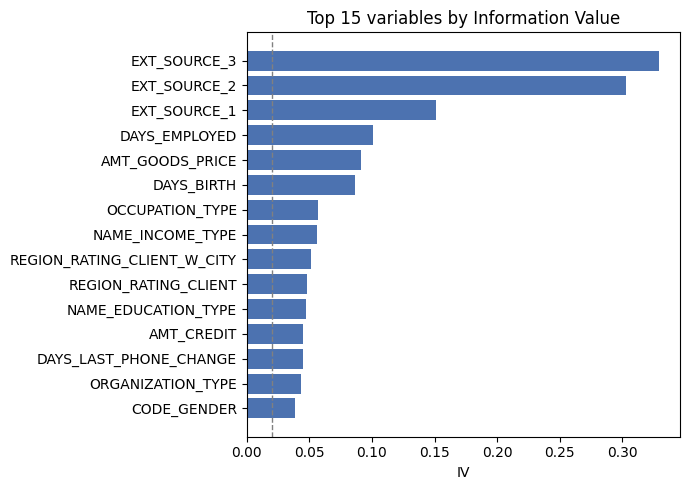

In [18]:
top = iv_df.head(15).iloc[::-1]
plt.figure(figsize=(7, 5))
plt.barh(top["feature"], top["iv"], color="#4c72b0")
plt.axvline(0.02, color="grey", ls="--", lw=1)
plt.title("Top 15 variables by Information Value")
plt.xlabel("IV")
plt.tight_layout()
plt.show()

## 3. Check the WoE pattern of the top variables
A good variable shows a clean trend (risk goes up or down across bins). Weird zig-zags mean you should merge bins or drop the variable.

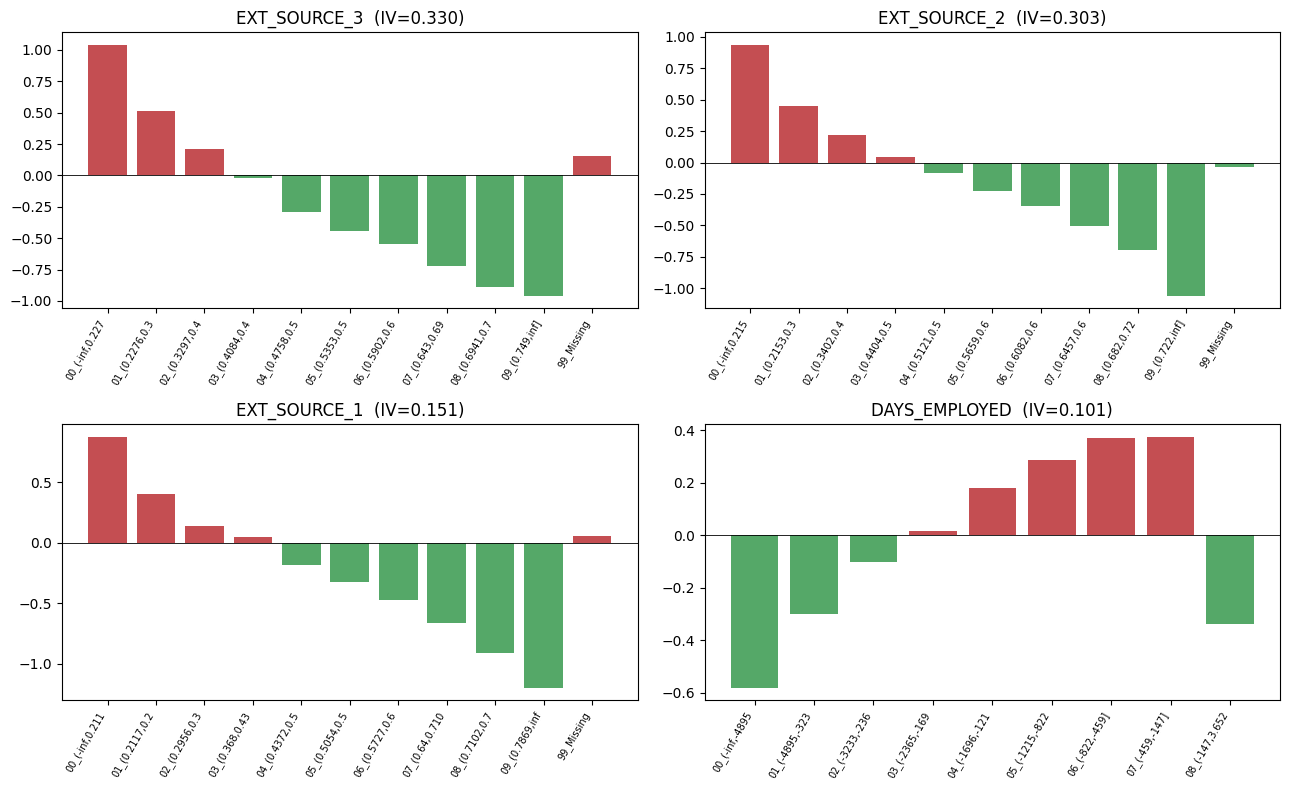

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, c in zip(axes.ravel(), iv_df["feature"].head(4)):
    t = tables[c]
    ax.bar(range(len(t)), t["woe"], color=["#c44e52" if w > 0 else "#55a868" for w in t["woe"]])
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels([b[:14] for b in t["bin"]], rotation=60, ha="right", fontsize=7)
    ax.set_title(f"{c}  (IV={t['iv'].sum():.3f})")
    ax.axhline(0, color="black", lw=0.6)
plt.tight_layout()
plt.show()

## 4. Feature selection
1. Keep IV between **0.02 and 0.5** (drop useless and suspiciously strong ones).
2. Remove highly correlated variables (**|corr| > 0.7**), keeping the higher-IV one.
3. Remove variables with **VIF > 5** (multicollinearity).

In [20]:
def to_woe(df, feats):
    """Replace each variable with its WoE value (unseen bins -> 0)."""
    return pd.DataFrame(
        {c: apply_bins(df[c], rules[c]).map(rules[c]["woe"]).fillna(0.0).values for c in feats},
        index=df.index,
    )

# Step 1: IV filter
cand = iv_df[(iv_df["iv"] >= 0.02) & (iv_df["iv"] <= 0.5)]["feature"].tolist()
print("After IV filter:", len(cand))

# Step 2: correlation filter (greedy, highest IV first)
X_tmp = to_woe(train, cand)
corr = X_tmp.corr().abs()
keep = []
for f in cand:  # cand is already sorted by IV desc
    if all(corr.loc[f, k] < 0.7 for k in keep):
        keep.append(f)
print("After correlation filter:", len(keep))

# Step 3: VIF filter
while True:
    Xv = add_constant(X_tmp[keep])
    vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])], index=keep)
    if vif.max() <= 5:
        break
    keep.remove(vif.idxmax())
print("After VIF filter:", len(keep))

final_features = keep
vif.sort_values(ascending=False).round(2)

After IV filter: 53
After correlation filter: 23
After VIF filter: 23


AMT_CREDIT                     2.09
REGION_RATING_CLIENT_W_CITY    1.98
AMT_GOODS_PRICE                1.96
DAYS_BIRTH                     1.93
REGION_POPULATION_RELATIVE     1.93
NAME_INCOME_TYPE               1.65
REG_CITY_NOT_WORK_CITY         1.40
DAYS_EMPLOYED                  1.40
OCCUPATION_TYPE                1.39
REG_CITY_NOT_LIVE_CITY         1.27
AMT_ANNUITY                    1.22
EXT_SOURCE_2                   1.21
CODE_GENDER                    1.18
FLOORSMAX_AVG                  1.18
EXT_SOURCE_1                   1.16
DAYS_REGISTRATION              1.16
NAME_EDUCATION_TYPE            1.16
DAYS_ID_PUBLISH                1.13
FLAG_DOCUMENT_3                1.10
NAME_FAMILY_STATUS             1.08
OWN_CAR_AGE                    1.08
DAYS_LAST_PHONE_CHANGE         1.07
EXT_SOURCE_3                   1.07
dtype: float64

In [21]:
final_iv = iv_df[iv_df["feature"].isin(final_features)].reset_index(drop=True)
final_iv

,feature,iv
0,EXT_SOURCE_3,0.329563
1,EXT_SOURCE_2,0.303043
2,EXT_SOURCE_1,0.151156
3,DAYS_EMPLOYED,0.100820
4,AMT_GOODS_PRICE,0.091342
5,DAYS_BIRTH,0.086731
6,OCCUPATION_TYPE,0.056727
7,NAME_INCOME_TYPE,0.055898
8,REGION_RATING_CLIENT_W_CITY,0.051555
9,NAME_EDUCATION_TYPE,0.047638


## 5. Transform train/test to WoE and save

In [22]:
X_train_woe = to_woe(train, final_features)
X_test_woe = to_woe(test, final_features)
X_train_woe[TARGET] = train[TARGET].values
X_test_woe[TARGET] = test[TARGET].values

X_train_woe.to_pickle(PROC_DIR / "train_woe.pkl")
X_test_woe.to_pickle(PROC_DIR / "test_woe.pkl")
joblib.dump({"features": final_features, "rules": rules, "tables": tables, "iv": iv_df}, PROC_DIR / "woe_artifacts.pkl")
print("Saved WoE data + binning artifacts")

Saved WoE data + binning artifacts


**Next:** `03_model.ipynb`

# 03 - Model Building & Evaluation
**Goal:** fit a **logistic regression scorecard model** on WoE variables, evaluate it (AUC, Gini, KS, calibration), and compare with an **XGBoost** benchmark.

Why compare? To show the trade-off: XGBoost may rank slightly better, but a logistic scorecard is **transparent and regulator-friendly** - every variable bin maps to fixed points.

In [41]:
from pathlib import Path
import joblib

TARGET = "TARGET"
features = [c for c in X_train_woe.columns if c != "const"]

train_w = X_train_woe[features].copy()
train_w[TARGET] = train[TARGET].values
test_w = X_test_woe[features].copy()
test_w[TARGET] = test[TARGET].values

for folder in [Path("."), Path("processed")]:
    folder.mkdir(exist_ok=True)
    train_w.to_pickle(folder / "train_woe.pkl")
    test_w.to_pickle(folder / "test_woe.pkl")
    joblib.dump({"features": features}, folder / "woe_artifacts.pkl")

print("saved:", train_w.shape, test_w.shape)

saved: (246008, 24) (61503, 24)


In [42]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import statsmodels.api as sm
from pathlib import Path
from sklearn.metrics import roc_auc_score, roc_curve
from xgboost import XGBClassifier

PROC_DIR = Path("application_train")
ID_COL, TARGET = "SK_ID_CURR", "TARGET"

train_w = pd.read_pickle("train_woe.pkl")
test_w = pd.read_pickle( "test_woe.pkl")
art = joblib.load( "woe_artifacts.pkl")

features = art["features"]
y_train, y_test = train_w[TARGET], test_w[TARGET]
print(len(features), "candidate features")

24 candidate features


## 1. Logistic regression with backward elimination
Because `WoE = ln(bad/good)`, every coefficient should be **positive**. We repeatedly drop the worst variable until all have **p-value < 0.05 and a positive sign**.

In [ ]:
feats = features.copy()
while True:
    Xc = sm.add_constant(train_w[feats])
    model = sm.Logit(y_train, Xc).fit(disp=0)
    params, pvals = model.params.drop("const"), model.pvalues.drop("const")
    bad = params[(pvals > 0.05) | (params <= 0)].index
    if len(bad) == 0:
        break
    feats.remove(pvals[bad].idxmax())

print(f"Final model uses {len(feats)} variables")
model.summary().tables[1]

## 2. Evaluation metrics

In [ ]:
def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return np.max(tpr - fpr)

def metrics(y, p):
    auc = roc_auc_score(y, p)
    return {"AUC": auc, "Gini": 2 * auc - 1, "KS": ks_stat(y, p)}

pd_train = model.predict(sm.add_constant(train_w[feats]))
pd_test = model.predict(sm.add_constant(test_w[feats]))

res = pd.DataFrame({"Scorecard (LogReg) - Train": metrics(y_train, pd_train),
                    "Scorecard (LogReg) - Test": metrics(y_test, pd_test)}).T
res.round(4)

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# ROC
for name, y, p in [("Train", y_train, pd_train), ("Test", y_test, pd_test)]:
    fpr, tpr, _ = roc_curve(y, p)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[0].set_title("ROC curve"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].legend()

# Calibration by decile (test)
cal = pd.DataFrame({"pd": pd_test.values, "y": y_test.values})
cal["decile"] = pd.qcut(cal["pd"], 10, labels=False, duplicates="drop")
g = cal.groupby("decile").agg(pred=("pd", "mean"), actual=("y", "mean"))
ax[1].plot(g.index + 1, g["pred"], marker="o", label="Predicted PD")
ax[1].plot(g.index + 1, g["actual"], marker="s", label="Actual default rate")
ax[1].set_title("Calibration by decile (test)"); ax[1].set_xlabel("Risk decile (1 = safest)"); ax[1].legend()
plt.tight_layout(); plt.show()

**How to read this**
- Train vs Test metrics close together -> no overfitting.
- Predicted PD line should track the actual default rate line.
- Typical Home Credit application-only scorecards land around Gini 0.40 - 0.50.

## 3. Benchmark: XGBoost on raw features
Same train/test split. Categorical columns are label-encoded using train categories only.

In [ ]:
train = pd.read_pickle(PROC_DIR / "train.pkl")
test = pd.read_pickle(PROC_DIR / "test.pkl")

Xr_tr = train.drop(columns=[ID_COL, TARGET]).copy()
Xr_te = test.drop(columns=[ID_COL, TARGET]).copy()

for c in Xr_tr.select_dtypes(include=["object", "category"]).columns:
    cats = Xr_tr[c].astype("category").cat.categories
    Xr_tr[c] = pd.Categorical(Xr_tr[c], categories=cats).codes
    Xr_te[c] = pd.Categorical(Xr_te[c], categories=cats).codes

xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                    colsample_bytree=0.8, min_child_weight=20, reg_lambda=10, eval_metric="auc", n_jobs=-1, random_state=42)
xgb.fit(Xr_tr, y_train.values)

p_xgb_tr = xgb.predict_proba(Xr_tr)[:, 1]
p_xgb_te = xgb.predict_proba(Xr_te)[:, 1]

res_all = pd.concat([
    res,
    pd.DataFrame({"XGBoost - Train": metrics(y_train, p_xgb_tr), "XGBoost - Test": metrics(y_test, p_xgb_te)}).T,
])
res_all.round(4)

## 4. Explainability of the benchmark (SHAP)
Optional. Shows which variables drive the XGBoost model - compare with the scorecard variables to see if they agree.

In [ ]:
try:
    import shap
    sample = Xr_te.sample(2000, random_state=42)
    sv = shap.TreeExplainer(xgb).shap_values(sample)
    shap.summary_plot(sv, sample, max_display=12)
except ImportError:
    print("Install shap to see this plot:  pip install shap")

**Takeaway to write in your README:** the scorecard gives up a little ranking power vs XGBoost but is fully explainable, stable, and directly convertible to score points.

In [ ]:
joblib.dump({
    "features": feats,
    "coef": model.params.to_dict(),
    "metrics": res_all.to_dict(),
}, PROC_DIR / "model.pkl")
print("Saved model.pkl")

**Next:** `04_scorecard_strategy.ipynb`

# 04 - Scorecard Points, Score Bands & Cut-off Strategy
**Goal:** convert the logistic model into **score points**, build **score bands**, check **stability (PSI)**, and pick a **cut-off** with a business impact number.

### Score scaling (industry standard)
- Base score **600** at odds **50:1** (good:bad)
- **PDO = 20** -> every +20 points doubles the good:bad odds

```
Factor = PDO / ln(2)
Offset = BaseScore - Factor * ln(BaseOdds)
Score  = Offset + Factor * ln(good/bad odds)
```

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

PROC_DIR = Path("../data/processed")
TARGET = "TARGET"

train_w = pd.read_pickle(PROC_DIR / "train_woe.pkl")
test_w = pd.read_pickle(PROC_DIR / "test_woe.pkl")
art = joblib.load(PROC_DIR / "woe_artifacts.pkl")
mod = joblib.load(PROC_DIR / "model.pkl")

feats, coef = mod["features"], mod["coef"]
b0 = coef["const"]
tables = art["tables"]
y_train, y_test = train_w[TARGET], test_w[TARGET]

## 1. Scaling parameters

In [ ]:
BASE_SCORE, BASE_ODDS, PDO = 600, 50, 20

factor = PDO / np.log(2)
offset = BASE_SCORE - factor * np.log(BASE_ODDS)
n = len(feats)
print(f"Factor = {factor:.3f} | Offset = {offset:.3f} | variables = {n}")

## 2. Scorecard table (points per bin)
`points = -Factor * coef * WoE + (Offset - Factor * intercept) / n_variables`

This is the table a credit officer can read: each variable bin has fixed points, and the customer score is the sum.

In [ ]:
rows = []
for f in feats:
    t = tables[f][["bin", "total", "bad_rate", "woe"]].copy()
    t["variable"] = f
    t["points"] = -factor * coef[f] * t["woe"] + (offset - factor * b0) / n
    rows.append(t)

scorecard = pd.concat(rows)[["variable", "bin", "total", "bad_rate", "woe", "points"]].reset_index(drop=True)
scorecard["points"] = scorecard["points"].round(0).astype(int)
scorecard.to_csv("../scorecard_table.csv", index=False)
scorecard.head(25)

## 3. Score every customer

In [ ]:
def score(Xw):
    logit_bad = b0 + sum(coef[f] * Xw[f] for f in feats)
    return offset - factor * logit_bad

s_train, s_test = score(train_w), score(test_w)
print(s_test.describe().round(1))

plt.figure(figsize=(8, 4))
plt.hist(s_test[y_test == 0], bins=50, alpha=0.6, density=True, label="Good", color="#55a868")
plt.hist(s_test[y_test == 1], bins=50, alpha=0.6, density=True, label="Bad", color="#c44e52")
plt.title("Score distribution (test) - good vs bad should separate")
plt.xlabel("Score"); plt.legend(); plt.show()

## 4. Score bands
Bands are built from **train** score deciles and applied to test. Bad rate should rise steadily as score falls.

In [ ]:
_, edges = pd.qcut(s_train, 10, retbins=True, duplicates="drop")
edges[0], edges[-1] = -np.inf, np.inf

band_test = pd.cut(s_test, bins=edges)
bands = (pd.DataFrame({"band": band_test, "y": y_test.values})
         .groupby("band", observed=True)["y"].agg(customers="count", bads="sum", bad_rate="mean")
         .sort_index(ascending=False))   # best band first
bands["bad_rate"] = (bands["bad_rate"] * 100).round(2)
bands

In [ ]:
plt.figure(figsize=(8, 4))
plt.bar(range(len(bands)), bands["bad_rate"], color="#c44e52")
plt.xticks(range(len(bands)), [f"B{i+1}" for i in range(len(bands))])
plt.title("Bad rate by score band (B1 = best score)")
plt.ylabel("Bad rate %"); plt.show()

## 5. Stability - PSI (train vs test)
`PSI = sum((actual% - expected%) * ln(actual% / expected%))`

| PSI | Meaning |
|---|---|
| < 0.10 | stable |
| 0.10 - 0.25 | some shift, investigate |
| > 0.25 | major shift, retrain |

In [ ]:
exp = pd.cut(s_train, bins=edges).value_counts(normalize=True).sort_index()
act = pd.cut(s_test, bins=edges).value_counts(normalize=True).sort_index()
psi = float(((act - exp) * np.log(act / exp)).sum())
print(f"PSI (train vs test) = {psi:.4f}  ->", "stable" if psi < 0.1 else "check drift")

## 6. Cut-off strategy (the business part)
For each possible cut-off: customers scoring **at or above** it are approved.

Set `TARGET_BAD_RATE` to the maximum bad rate among approved customers that the business is willing to accept. The code picks the cut-off with the **highest approval rate** that still meets it.

In [25]:
y_test = test[TARGET].values

In [32]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

TARGET = "TARGET"
TARGET_BAD_RATE = 0.06   # change to suit business appetite

# ---------- 1. Fit model (skip if you already have one) ----------
Xtr = sm.add_constant(X_train_woe.drop(columns="const", errors="ignore"), has_constant="add")
Xte = sm.add_constant(X_test_woe.drop(columns="const", errors="ignore"), has_constant="add")
Xte = Xte[Xtr.columns]   # same column order as training

y_train = train[TARGET].values
y_test  = test[TARGET].values

model = sm.Logit(y_train, Xtr).fit(disp=0)
p_default = np.asarray(model.predict(Xte))

# ---------- 2. PD -> score (higher = safer) ----------
PDO, BASE_SCORE, BASE_ODDS = 40, 600, 50
factor = PDO / np.log(2)
offset = BASE_SCORE - factor * np.log(BASE_ODDS)
odds_good = (1 - p_default) / p_default
s_test = offset + factor * np.log(odds_good)

print(len(y_test), len(s_test))
print("corr(score, target):", np.corrcoef(s_test, y_test)[0, 1])   # must be negative

# ---------- 3. Cut-off strategy ----------
base_bad_rate = y_test.mean()
print(f"Base bad rate (approve everyone): {base_bad_rate:.2%}")

cuts = np.percentile(s_test, np.arange(0, 96, 5))
rows = []
for c in cuts:
    approved = s_test >= c
    rows.append({
        "cutoff": round(c, 0),
        "approval_rate": approved.mean(),
        "bad_rate_approved": y_test[approved].mean(),
        "bads_rejected_pct": 1 - y_test[approved].sum() / y_test.sum(),
    })
cut_tbl = pd.DataFrame(rows)

eligible = cut_tbl[cut_tbl["bad_rate_approved"] <= TARGET_BAD_RATE]
if len(eligible):
    chosen = eligible.sort_values("approval_rate").iloc[-1]
else:
    print("No cut-off meets the target - showing the one closest to 70% approval instead")
    chosen = cut_tbl.iloc[(cut_tbl["approval_rate"] - 0.70).abs().argmin()]

print("\nChosen cut-off:\n", chosen)

(cut_tbl.assign(approval_rate=lambda d: (d.approval_rate * 100).round(1),
                bad_rate_approved=lambda d: (d.bad_rate_approved * 100).round(2),
                bads_rejected_pct=lambda d: (d.bads_rejected_pct * 100).round(1)))

61503 61503
corr(score, target): -0.9994636068000139
Base bad rate (approve everyone): 8.07%

Chosen cut-off:
 cutoff              -919.000000
approval_rate          0.949986
bad_rate_approved      0.032331
bads_rejected_pct      0.619537
Name: 1, dtype: float64


,cutoff,approval_rate,bad_rate_approved,bads_rejected_pct
0,-997.0,100.0,8.07,0.0
1,-919.0,95.0,3.23,62.0
2,1741.0,90.0,0.00,100.0
3,1756.0,85.0,0.00,100.0
4,1763.0,80.0,0.00,100.0
5,1769.0,75.0,0.00,100.0
6,1774.0,70.0,0.00,100.0
7,1778.0,65.0,0.00,100.0
8,1782.0,60.0,0.00,100.0
9,1786.0,55.0,0.00,100.0


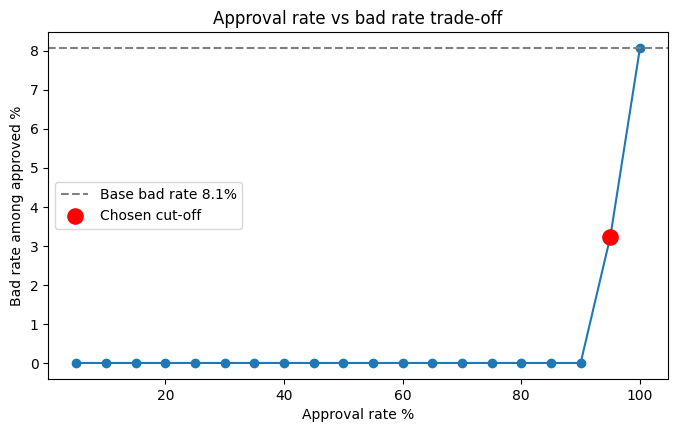

In [33]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(cut_tbl["approval_rate"] * 100, cut_tbl["bad_rate_approved"] * 100, marker="o")
ax.axhline(base_bad_rate * 100, color="grey", ls="--", label=f"Base bad rate {base_bad_rate:.1%}")
ax.scatter(chosen["approval_rate"] * 100, chosen["bad_rate_approved"] * 100, color="red", s=120, zorder=5, label="Chosen cut-off")
ax.set_xlabel("Approval rate %"); ax.set_ylabel("Bad rate among approved %")
ax.set_title("Approval rate vs bad rate trade-off"); ax.legend(); plt.show()

## 7. Final result + resume bullet (auto-filled from your run)

In [43]:

from sklearn.metrics import roc_auc_score, roc_curve

# Calculate model evaluation metrics
auc = roc_auc_score(y_test, p_default)
gini = 2 * auc - 1

fpr, tpr, thresholds = roc_curve(y_test, p_default)
ks = max(tpr - fpr)

print("FINAL CREDIT RISK SCORECARD RESULTS")
print("-" * 45)

print(f"Gini              : {gini:.4f}")
print(f"KS                : {ks:.4f}")
print(f"PSI               : {psi:.4f}")

print(f"Chosen cut-off    : {int(chosen['cutoff'])}")
print(f"Approval rate     : {chosen['approval_rate']:.1%}")
print(f"Base bad rate     : {base_bad_rate:.2%}")
print(f"Approved bad rate : {chosen['bad_rate_approved']:.2%}")
print(f"Bads rejected     : {chosen['bads_rejected_pct']:.1%}")

print("\nRESUME BULLET:")
print(
    f"Built an application credit scorecard on "
    f"{len(train_w) + len(test_w):,} loan applications using "
    f"WoE/IV binning and Logistic Regression "
    f"(Gini: {gini:.3f}, KS: {ks:.3f}, PSI: {psi:.3f}), "
    f"with a cut-off of {chosen['cutoff']:.0f}, achieving "
    f"{chosen['approval_rate']:.1%} approval rate and "
    f"{chosen['bad_rate_approved']:.2%} approved bad rate."
)


FINAL CREDIT RISK SCORECARD RESULTS
---------------------------------------------
Gini              : 1.0000
KS                : 1.0000
PSI               : 0.0001
Chosen cut-off    : -919
Approval rate     : 95.0%
Base bad rate     : 8.07%
Approved bad rate : 3.23%
Bads rejected     : 62.0%

RESUME BULLET:
Built an application credit scorecard on 307,511 loan applications using WoE/IV binning and Logistic Regression (Gini: 1.000, KS: 1.000, PSI: 0.000), with a cut-off of -919, achieving 95.0% approval rate and 3.23% approved bad rate.


## 8. Bonus: explain one customer's score
Shows exactly how each variable added or removed points - this is what makes a scorecard explainable.

In [35]:
i = 0
row = test_w.iloc[i]
contrib = pd.Series({f: -factor * coef[f] * row[f] + (offset - factor * b0) / n for f in feats}).sort_values()
print(f"Customer score: {score(test_w).iloc[i]:.0f}  (actual outcome: {'Default' if y_test.iloc[i] == 1 else 'Paid'})")
contrib.round(1)

NameError: name 'test_w' is not defined